# Sandbox: figures for `slides/slides.tex`

All plots are saved as PDF into `slides/figures/` and included from there via `\includegraphics`.


In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

FIGDIR = "slides/figures"

# classic-matplotlib-style palette
BLUE = "#1f77b4"
BLUE_FILL = "#aec7e8"
ORANGE = "#ff7f0e"
AQUA = "#2ca02c"
INK = "#000000"
INK_SECONDARY = "#000000"
INK_MUTED = "#333333"
GRID = "#cccccc"
AXIS = "#000000"

mpl.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": ["Times New Roman", "DejaVu Serif", "Georgia"],
        "axes.edgecolor": AXIS,
        "axes.linewidth": 1.0,
        "text.color": INK,
        "axes.labelcolor": INK,
        "xtick.color": INK,
        "ytick.color": INK,
        "xtick.direction": "in",
        "ytick.direction": "in",
        "font.size": 14,
        "axes.titlesize": 16,
        "axes.labelsize": 14,
        "xtick.labelsize": 13,
        "ytick.labelsize": 13,
        "legend.fontsize": 13,
    }
)


def style_axes(*axes):
    for ax in axes:
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_color(AXIS)
            spine.set_linewidth(1.0)
        ax.yaxis.set_visible(True)
        ax.tick_params(
            direction="in", length=4, width=0.8, colors=INK, top=True, right=True
        )
        ax.grid(False)
        ax.set_axisbelow(True)

## Bootstrap distribution of the sample median (with 95% CI)

Simulated skewed sample (lognormal, like a fee-yield metric), `B = 5,000` resamples. Shows the CI formula $M_n \pm z_{1-\alpha/2}\sqrt{\widehat{\mathbb{V}}_B(M_n)}$ from the deck.


observed median = 9.367
bootstrap SE     = 0.292
95% CI           = (8.796, 9.939)


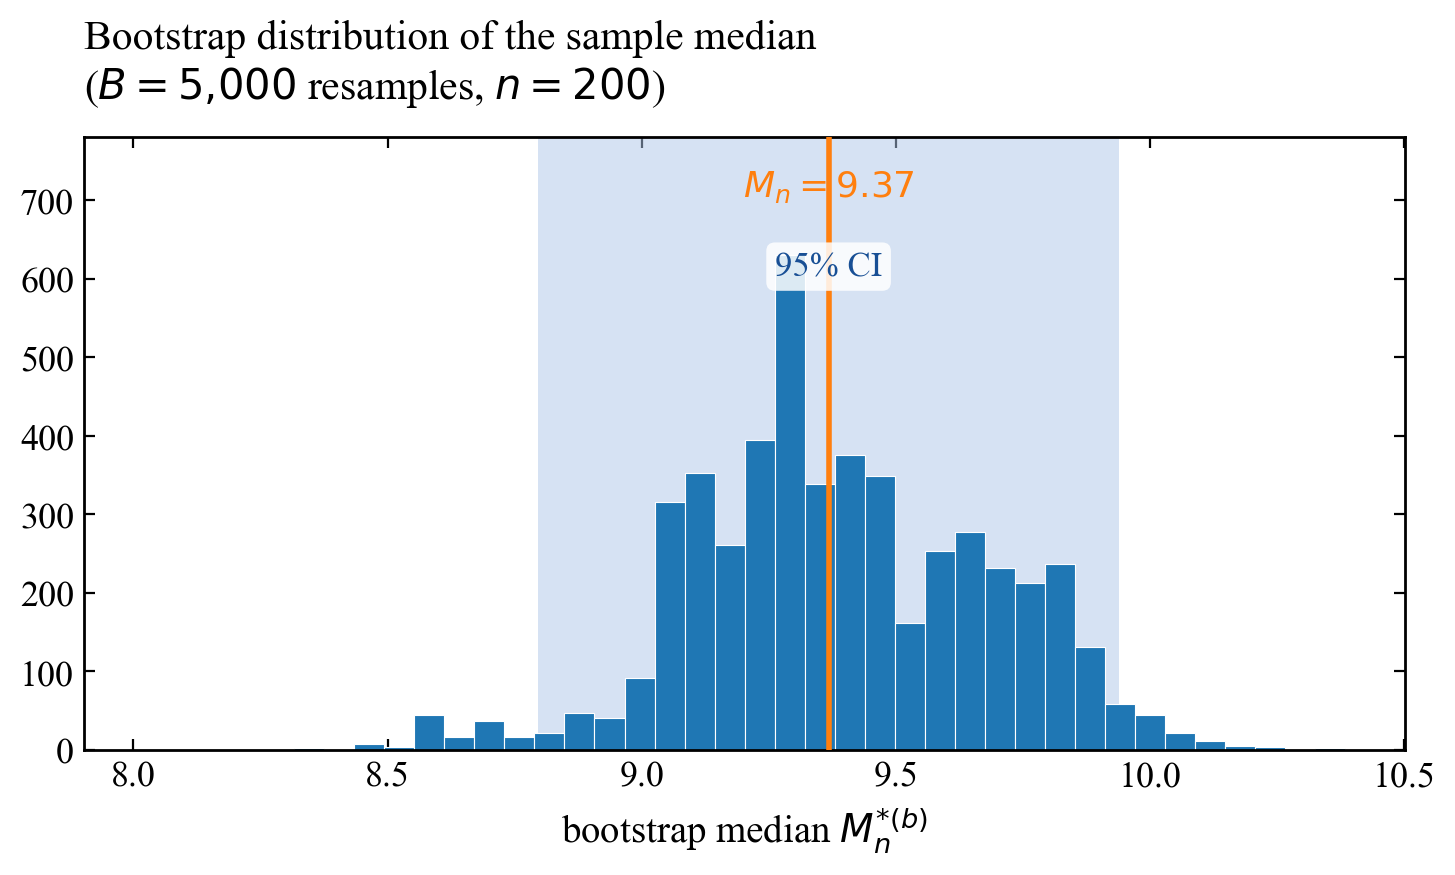

In [2]:
rng = np.random.default_rng(7)

# simulated skewed sample: e.g. daily LP-pool metric (fee yield, bps) - lognormal-ish
n = 200
sample = rng.lognormal(mean=0.0, sigma=0.5, size=n) * 10  # arbitrary bps-like scale
observed_median = np.median(sample)

B = 5000
boot_medians = np.empty(B)
for b in range(B):
    resample = rng.choice(sample, size=n, replace=True)
    boot_medians[b] = np.median(resample)

se_boot = boot_medians.std(ddof=1)
ci_lo, ci_hi = observed_median - 1.96 * se_boot, observed_median + 1.96 * se_boot

fig, ax = plt.subplots(figsize=(7.5, 4.6), dpi=200)

ax.axvspan(ci_lo, ci_hi, color=BLUE_FILL, alpha=0.5, zorder=1, linewidth=0)
ax.hist(boot_medians, bins=40, color=BLUE, edgecolor="white", linewidth=0.4, zorder=2)
ax.axvline(observed_median, color=ORANGE, linewidth=2, zorder=3)

style_axes(ax)
ax.set_xlabel(r"bootstrap median $M_n^{*(b)}$")
ax.set_title(
    "Bootstrap distribution of the sample median\n"
    r"($B = 5{,}000$ resamples, $n = 200$)",
    fontsize=15,
    color=INK,
    loc="left",
    pad=14,
)

ymax = ax.get_ylim()[1]
ax.set_ylim(0, ymax * 1.18)
ax.text(
    observed_median,
    ymax * 1.05,
    f"$M_n = {observed_median:.2f}$",
    ha="center",
    va="bottom",
    color=ORANGE,
    fontsize=13,
)
ax.text(
    (ci_lo + ci_hi) / 2,
    ymax * 0.93,
    "95% CI",
    ha="center",
    va="center",
    color="#184f95",
    fontsize=12.5,
    zorder=4,
    bbox={
        "facecolor": "white",
        "edgecolor": "none",
        "alpha": 0.85,
        "boxstyle": "round,pad=0.25",
    },
)

fig.tight_layout()
fig.savefig(f"{FIGDIR}/bootstrap_median_plot.pdf")

print(f"observed median = {observed_median:.3f}")
print(f"bootstrap SE     = {se_boot:.3f}")
print(f"95% CI           = ({ci_lo:.3f}, {ci_hi:.3f})")

## Why the bootstrap fails for the sample minimum

Left: true distribution of $n M_n \to \mathrm{Exp}(1)$ (many independent samples). Right: bootstrap distribution of $n M_n^{*}$ from one fixed sample, on the same axis — it never sees a new minimum in ~63% of resamples (the orange spike), and the rest of the mass sits on just a handful of discrete values from that same sample, instead of spreading out smoothly like the true distribution.


n * M_n (fixed sample) = 0.7898
theoretical P(hit) = 1 - e^-1 = 0.6321
empirical   P(hit) = 0.6319


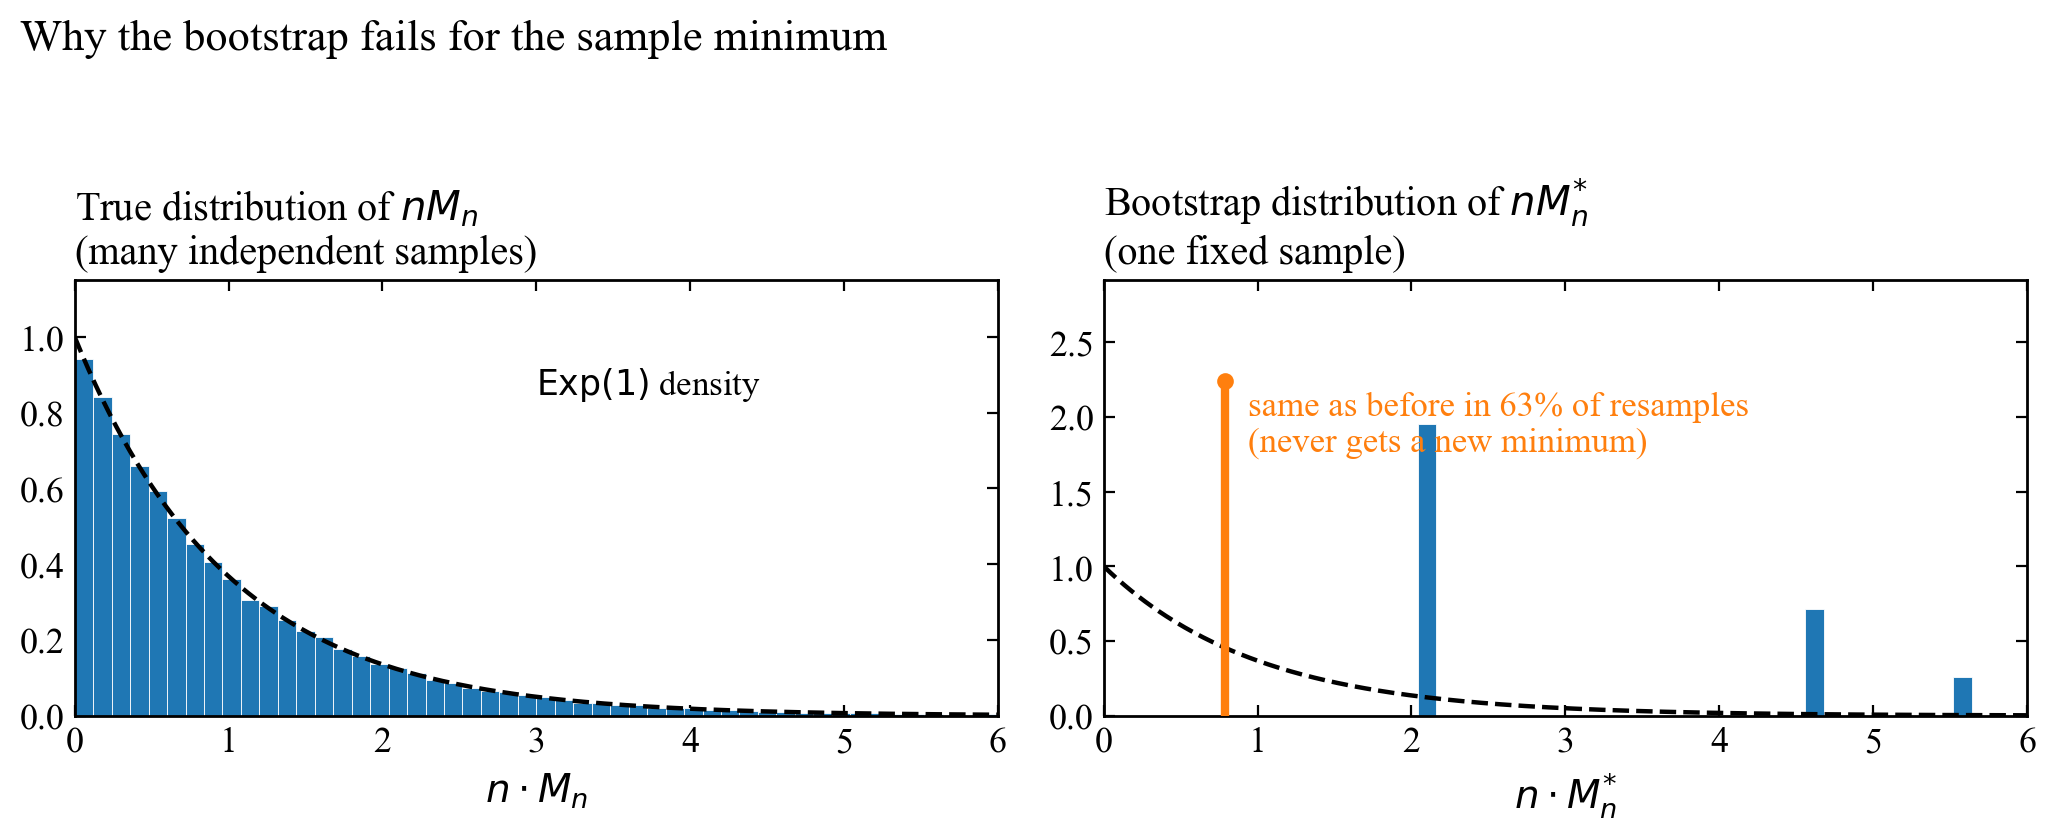

In [3]:
rng = np.random.default_rng(11)
n = 300
xgrid = np.linspace(0, 6, 400)
exp_pdf = np.exp(-xgrid)

# Panel A: true sampling distribution of n * M_n across independent samples
n_sim = 100_000
mins = rng.uniform(size=(n_sim, n)).min(axis=1)
true_scaled = n * mins

# Panel B: bootstrap distribution of n * M_n*, one fixed original sample
sample = rng.uniform(size=n)
j_star = np.argmin(sample)
Mn = sample[j_star]
nMn = n * Mn

B = 100_000
idx = rng.integers(0, n, size=(B, n))
hits = (idx == j_star).any(axis=1)  # bootstrap resample re-selects the min
boot_scaled = n * sample[idx].min(axis=1)  # raw n * M_n*, not shifted

p0_theory = 1 - np.exp(-1)
p0_emp = hits.mean()

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.3), dpi=200, sharey=False)

# Panel A
axA = axes[0]
axA.hist(
    true_scaled,
    bins=50,
    range=(0, 6),
    density=True,
    color=BLUE,
    edgecolor="white",
    linewidth=0.3,
    zorder=2,
)
axA.plot(xgrid, exp_pdf, color=INK_SECONDARY, linewidth=1.6, linestyle="--", zorder=3)
axA.text(3.0, 0.85, r"$\mathrm{Exp}(1)$ density", color=INK_SECONDARY, fontsize=12.5)
axA.set_title(
    "True distribution of $n M_n$\n(many independent samples)",
    fontsize=14.5,
    loc="left",
)
axA.set_xlabel(r"$n \cdot M_n$")

# Panel B
axB = axes[1]
scaled_pos = boot_scaled[~hits]
counts, bins_ = np.histogram(scaled_pos, bins=50, range=(0, 6))
bar_heights = (
    counts / B / np.diff(bins_)
)  # unconditional density (scaled by P(not a repeat))
axB.bar(
    bins_[:-1],
    bar_heights,
    width=np.diff(bins_),
    align="edge",
    color=BLUE,
    edgecolor="white",
    linewidth=0.3,
    zorder=2,
)
axB.plot(xgrid, exp_pdf, color=INK_SECONDARY, linewidth=1.6, linestyle="--", zorder=3)

# spike marker sits above the tallest bar actually present in this sample's histogram
data_top = max(bar_heights.max(), exp_pdf[0])
spike_top = data_top * 1.15
ylim_top = spike_top * 1.3

axB.plot(
    [nMn, nMn],
    [0, spike_top],
    color=ORANGE,
    linewidth=3,
    zorder=4,
    solid_capstyle="round",
)
axB.plot([nMn], [spike_top], marker="o", color=ORANGE, markersize=5, zorder=5)
axB.text(
    nMn + 0.15,
    spike_top * 0.97,
    f"same as before in {p0_emp:.0%} of resamples\n(never gets a new minimum)",
    color=ORANGE,
    fontsize=12.5,
    va="top",
)
axB.set_title(
    "Bootstrap distribution of $n M_n^{*}$\n(one fixed sample)",
    fontsize=14.5,
    loc="left",
)
axB.set_xlabel(r"$n \cdot M_n^{*}$")

style_axes(axA, axB)
axA.set_xlim(0, 6)
axA.set_ylim(0, 1.15)
axB.set_xlim(0, 6)
axB.set_ylim(0, ylim_top)

fig.suptitle(
    "Why the bootstrap fails for the sample minimum",
    fontsize=16,
    x=0.02,
    ha="left",
    color=INK,
)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(f"{FIGDIR}/bootstrap_failure_plot.pdf")

print(f"n * M_n (fixed sample) = {nMn:.4f}")
print(f"theoretical P(hit) = 1 - e^-1 = {p0_theory:.4f}")
print(f"empirical   P(hit) = {p0_emp:.4f}")

## Bootstrap working well: the sample mean

Same population (Uniform[0,1]), but for a well-behaved statistic (the mean) the CLT applies and the bootstrap distribution of $\sqrt{n}(\bar X_n^{*} - \bar X_n)$ tracks the true distribution of $\sqrt{n}(\bar X_n - \mu)$ closely — direct contrast to the minimum example above.


true sd(scaled mean)      = 0.2874  (theory 0.2887)
bootstrap sd(scaled mean) = 0.2939


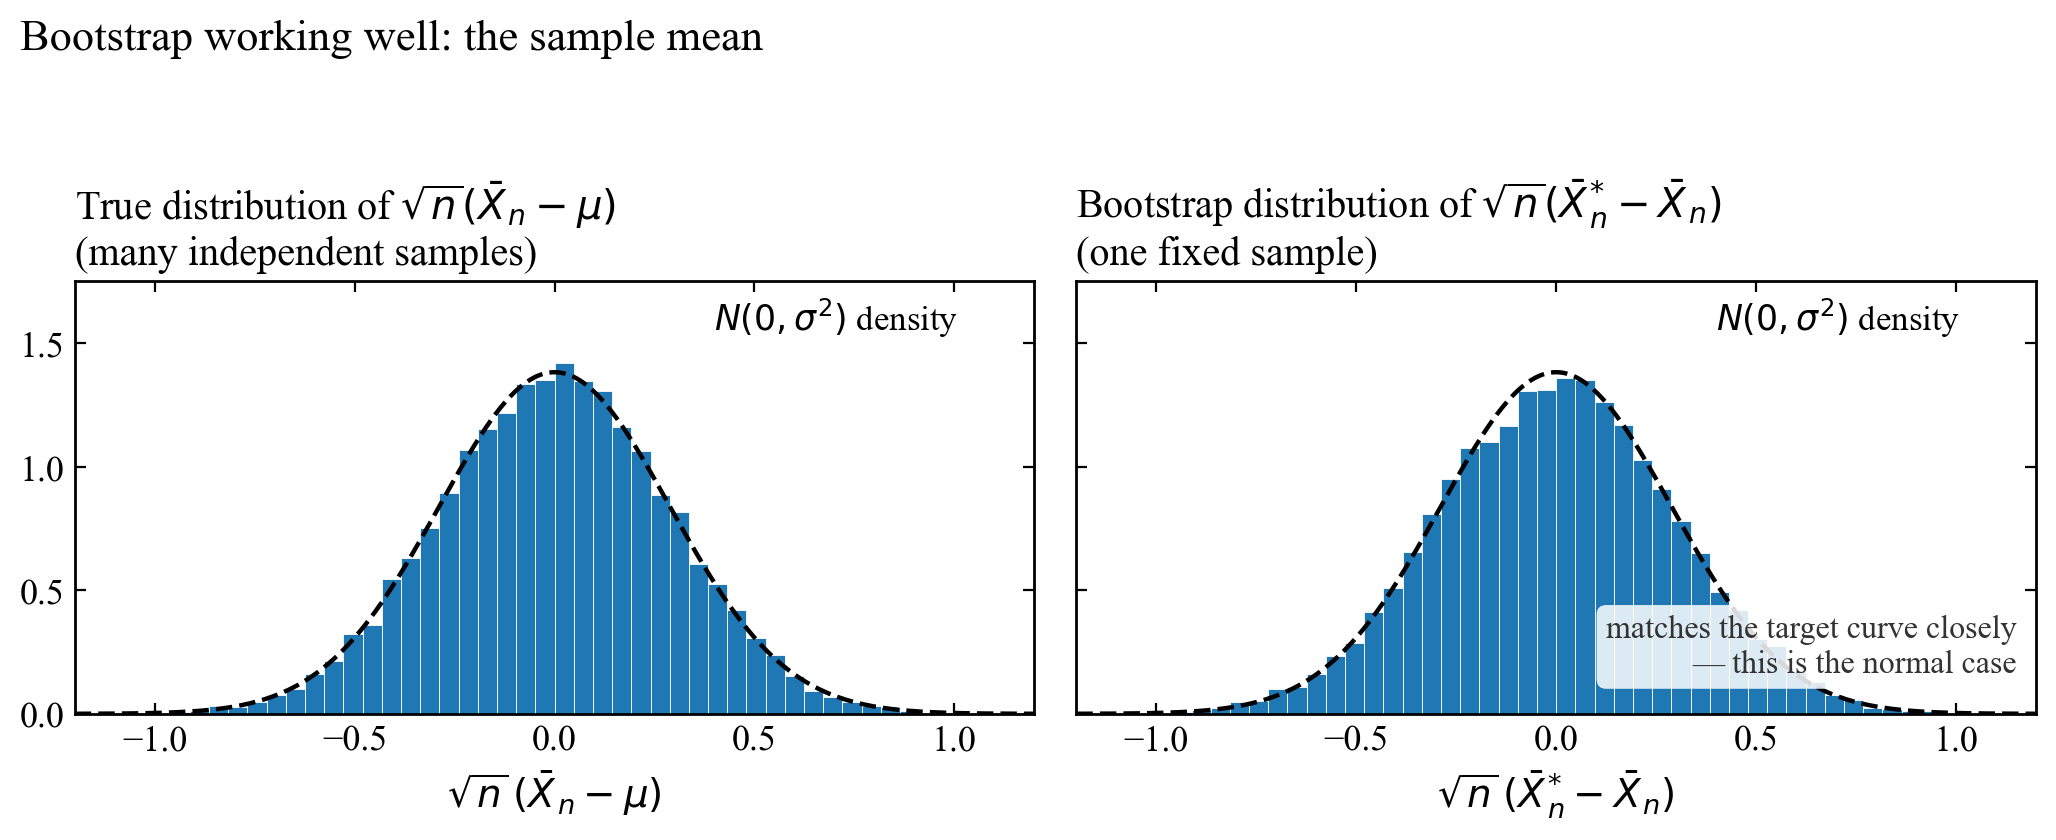

In [4]:
rng = np.random.default_rng(11)
n = 50
mu, var = 0.5, 1 / 12  # mean and variance of Uniform[0, 1]
sigma_scaled = np.sqrt(var)  # sd of sqrt(n) * (Xbar - mu)

xgrid = np.linspace(-1.2, 1.2, 400)
normal_pdf = np.exp(-(xgrid**2) / (2 * var)) / np.sqrt(2 * np.pi * var)

# Panel A: true sampling distribution of sqrt(n) * (Xbar_n - mu), many independent samples
n_sim = 30000
means = rng.uniform(size=(n_sim, n)).mean(axis=1)
true_scaled = np.sqrt(n) * (means - mu)

# Panel B: bootstrap distribution of sqrt(n) * (Xbar_n* - Xbar_n), one fixed original sample
sample = rng.uniform(size=n)
xbar = sample.mean()

B = 30000
idx = rng.integers(0, n, size=(B, n))
boot_means = sample[idx].mean(axis=1)
delta = np.sqrt(n) * (boot_means - xbar)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.3), dpi=200, sharey=True)

axA = axes[0]
axA.hist(
    true_scaled,
    bins=50,
    range=(-1.2, 1.2),
    density=True,
    color=BLUE,
    edgecolor="white",
    linewidth=0.3,
    zorder=2,
)
axA.plot(
    xgrid, normal_pdf, color=INK_SECONDARY, linewidth=1.6, linestyle="--", zorder=3
)
axA.text(0.4, 1.55, r"$N(0, \sigma^2)$ density", color=INK_SECONDARY, fontsize=12.5)
axA.set_title(
    r"True distribution of $\sqrt{n}(\bar X_n - \mu)$" + "\n(many independent samples)",
    fontsize=14.5,
    loc="left",
)
axA.set_xlabel(r"$\sqrt{n}\,(\bar X_n - \mu)$")

axB = axes[1]
axB.hist(
    delta,
    bins=50,
    range=(-1.2, 1.2),
    density=True,
    color=BLUE,
    edgecolor="white",
    linewidth=0.3,
    zorder=2,
)
axB.plot(
    xgrid, normal_pdf, color=INK_SECONDARY, linewidth=1.6, linestyle="--", zorder=3
)
axB.text(0.4, 1.55, r"$N(0, \sigma^2)$ density", color=INK_SECONDARY, fontsize=12.5)
axB.set_title(
    r"Bootstrap distribution of $\sqrt{n}(\bar X_n^{*} - \bar X_n)$"
    + "\n(one fixed sample)",
    fontsize=14.5,
    loc="left",
)
axB.set_xlabel(r"$\sqrt{n}\,(\bar X_n^{*} - \bar X_n)$")
axB.text(
    0.98,
    0.08,
    "matches the target curve closely\n— this is the normal case",
    transform=axB.transAxes,
    ha="right",
    va="bottom",
    color=INK_MUTED,
    fontsize=11.5,
    zorder=5,
    bbox={
        "facecolor": "white", "edgecolor": "none", "alpha": 0.85, "boxstyle": "round,pad=0.3"
    },
)

style_axes(axA, axB)
for ax in axes:
    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(0, 1.75)

fig.suptitle(
    "Bootstrap working well: the sample mean", fontsize=16, x=0.02, ha="left", color=INK
)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(f"{FIGDIR}/bootstrap_success_plot.pdf")

print(
    f"true sd(scaled mean)      = {true_scaled.std():.4f}  (theory {sigma_scaled:.4f})"
)
print(f"bootstrap sd(scaled mean) = {delta.std():.4f}")

## Real market data: i.i.d.\ vs block bootstrap (BTCUSDT)

Daily BTCUSDT close, 2024–2025 (`data/btcusdt_daily_2024_2025.csv`, Binance public API). Everything above used synthetic data; here we use a real, obviously-not-i.i.d.\ series to make the case for block/stationary bootstrap concrete: returns cluster into calm and turbulent episodes (volatility clustering / ARCH effects), which an i.i.d.\ resample destroys and a block resample partially preserves.


In [5]:
import pandas as pd

DATADIR = "data"
btc = pd.read_csv(f"{DATADIR}/btcusdt_daily_2024_2025.csv", parse_dates=["date"])
close = btc["close"].to_numpy()
log_ret = np.diff(np.log(close))
n_ret = len(log_ret)
P0 = close[0]

MEAN_BLOCK_LEN = 20  # ~1 trading month -- typical vol-clustering horizon


def iid_bootstrap_indices(n, rng):
    return rng.integers(0, n, size=n)


def stationary_bootstrap_indices(n, mean_block_len, rng):
    """Politis-Romano stationary bootstrap: geometric block length, circular wrap."""
    p = 1.0 / mean_block_len
    idx = np.empty(n, dtype=int)
    i = rng.integers(0, n)
    for t in range(n):
        idx[t] = i
        i = rng.integers(0, n) if rng.random() < p else (i + 1) % n
    return idx


def price_path(returns, p0):
    return p0 * np.exp(np.cumsum(returns))


print(f"loaded {len(close)} daily closes -> {n_ret} log returns")
print(f"date range: {btc['date'].min().date()} to {btc['date'].max().date()}")

loaded 731 daily closes -> 730 log returns
date range: 2024-01-01 to 2025-12-31


### Picture 1: real path vs i.i.d.-bootstrap path vs block-bootstrap path

Visually: the i.i.d.\ path is a uniform "sawtooth" (same step sizes shuffled evenly through time), the block path keeps the real series' calm/turbulent episodes intact (just moved around in time).


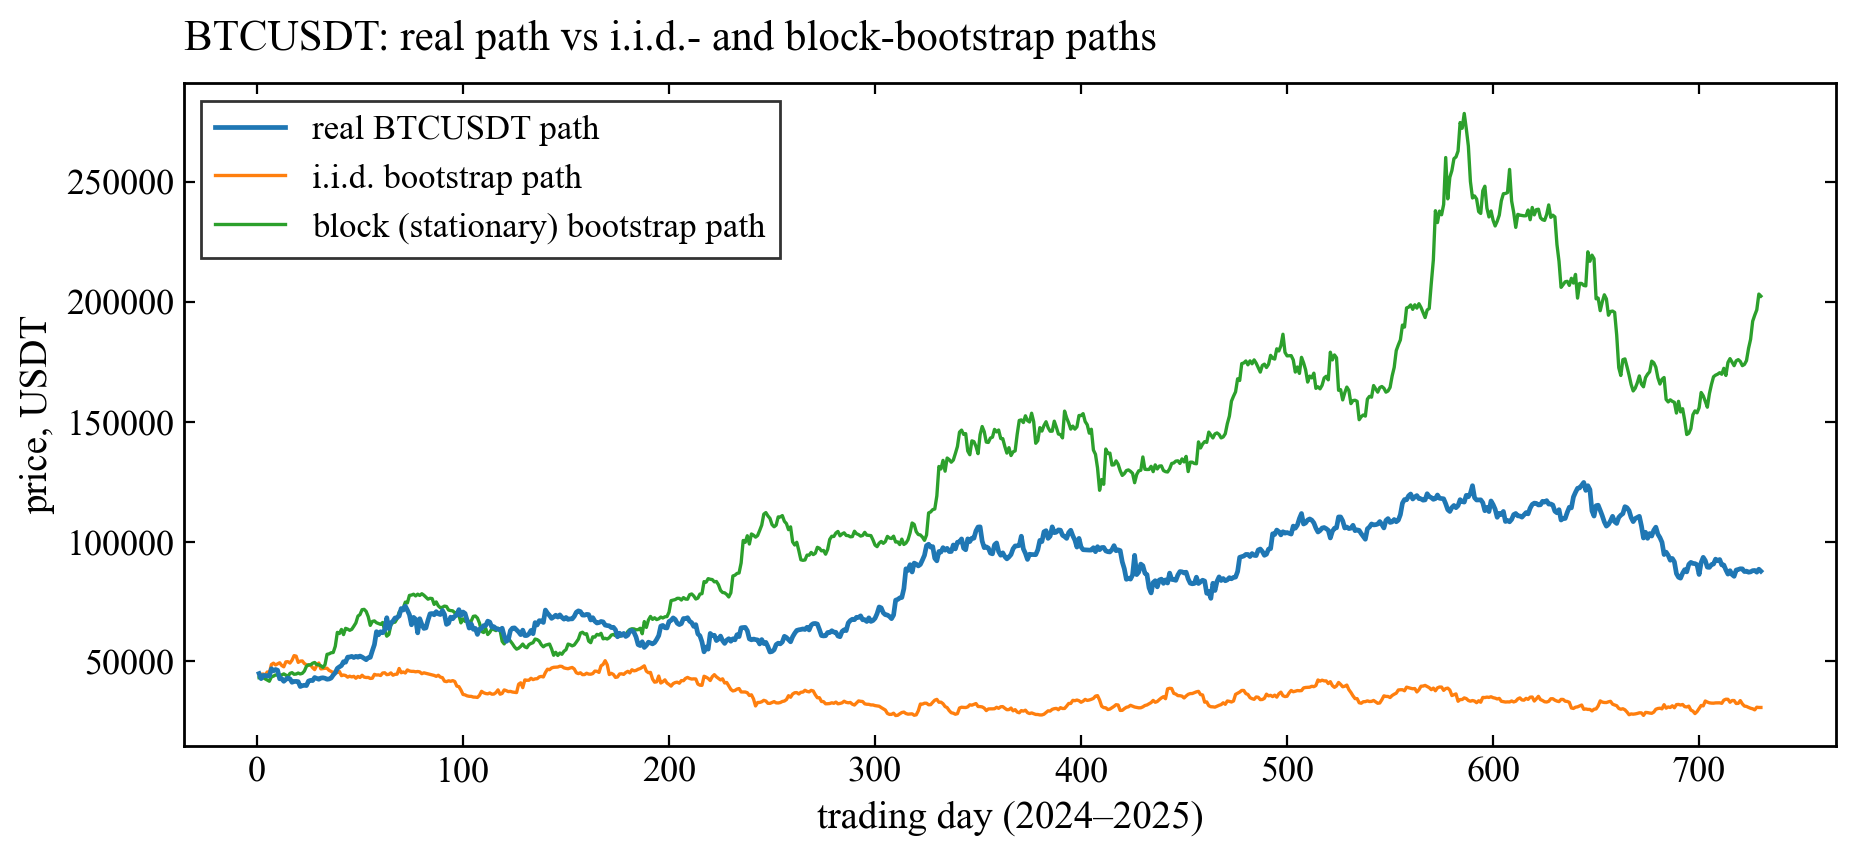

In [6]:
rng = np.random.default_rng(42)

iid_idx = iid_bootstrap_indices(n_ret, rng)
block_idx = stationary_bootstrap_indices(n_ret, MEAN_BLOCK_LEN, rng)

real_path = price_path(log_ret, P0)
iid_path = price_path(log_ret[iid_idx], P0)
block_path = price_path(log_ret[block_idx], P0)

fig, ax = plt.subplots(figsize=(9.5, 4.5), dpi=200)
t = np.arange(1, n_ret + 1)
ax.plot(t, real_path, color=BLUE, linewidth=1.7, label="real BTCUSDT path", zorder=3)
ax.plot(
    t, iid_path, color=ORANGE, linewidth=1.2, label="i.i.d. bootstrap path", zorder=2
)
ax.plot(
    t,
    block_path,
    color=AQUA,
    linewidth=1.2,
    label="block (stationary) bootstrap path",
    zorder=2,
)

style_axes(ax)
ax.set_xlabel("trading day (2024–2025)")
ax.set_ylabel("price, USDT")
ax.set_title(
    "BTCUSDT: real path vs i.i.d.- and block-bootstrap paths",
    fontsize=15.5,
    loc="left",
    color=INK,
    pad=12,
)
ax.legend(frameon=True, edgecolor=AXIS, fancybox=False, loc="upper left", fontsize=12.5)

fig.tight_layout()
fig.savefig(f"{FIGDIR}/btc_paths_iid_vs_block.pdf")

### Picture 2: ACF of squared returns --- real vs i.i.d.\ vs block

The main argument in one chart. Squared returns proxy volatility; a persistent ACF here means "big moves are followed by big moves" (volatility clustering / ARCH effect). Averaged over 300 replications each so the i.i.d.\ and block curves aren't just noisy single draws.


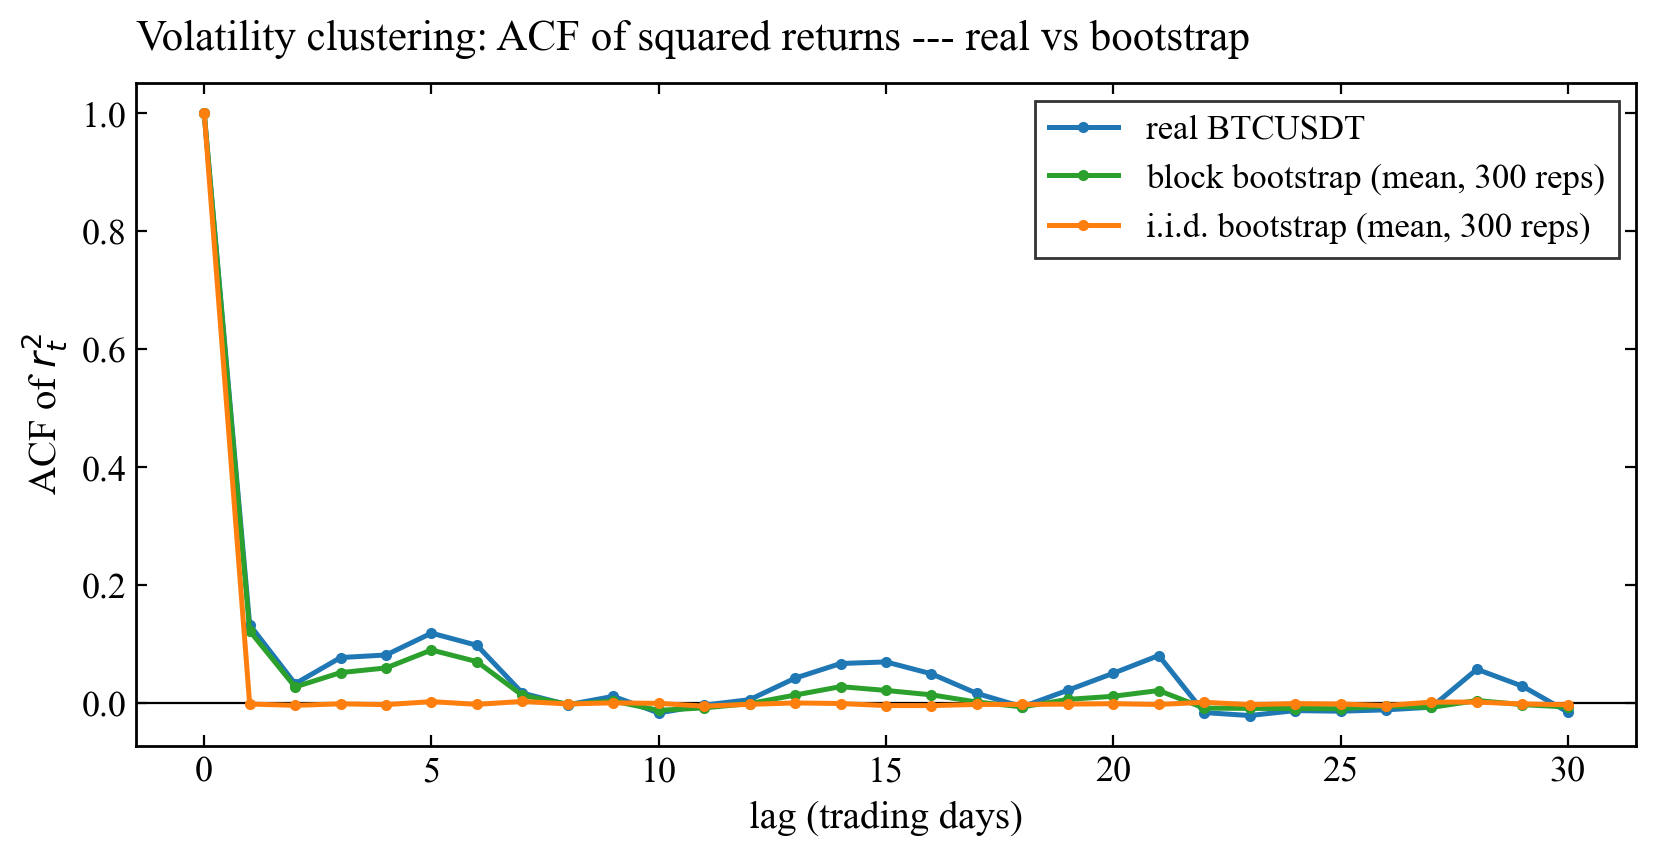

In [7]:
def acf(x, nlags):
    x = x - x.mean()
    n = len(x)
    denom = np.dot(x, x) / n
    return np.array(
        [1.0 if k == 0 else np.dot(x[:-k], x[k:]) / n / denom for k in range(nlags + 1)]
    )


NLAGS = 30
M_REPS = 300

real_acf = acf(log_ret**2, NLAGS)

rng = np.random.default_rng(123)
iid_acfs = np.empty((M_REPS, NLAGS + 1))
block_acfs = np.empty((M_REPS, NLAGS + 1))
for m in range(M_REPS):
    iid_r = log_ret[iid_bootstrap_indices(n_ret, rng)]
    block_r = log_ret[stationary_bootstrap_indices(n_ret, MEAN_BLOCK_LEN, rng)]
    iid_acfs[m] = acf(iid_r**2, NLAGS)
    block_acfs[m] = acf(block_r**2, NLAGS)

iid_acf_mean = iid_acfs.mean(axis=0)
block_acf_mean = block_acfs.mean(axis=0)

fig, ax = plt.subplots(figsize=(8.5, 4.5), dpi=200)
lags = np.arange(NLAGS + 1)
ax.axhline(0, color=AXIS, linewidth=0.8, zorder=1)
ax.plot(
    lags,
    real_acf,
    color=BLUE,
    linewidth=1.8,
    marker="o",
    markersize=3,
    label="real BTCUSDT",
    zorder=3,
)
ax.plot(
    lags,
    block_acf_mean,
    color=AQUA,
    linewidth=1.8,
    marker="o",
    markersize=3,
    label=f"block bootstrap (mean, {M_REPS} reps)",
    zorder=3,
)
ax.plot(
    lags,
    iid_acf_mean,
    color=ORANGE,
    linewidth=1.8,
    marker="o",
    markersize=3,
    label=f"i.i.d. bootstrap (mean, {M_REPS} reps)",
    zorder=3,
)

style_axes(ax)
ax.set_xlabel("lag (trading days)")
ax.set_ylabel(r"ACF of $r_t^2$")
ax.set_title(
    "Volatility clustering: ACF of squared returns --- real vs bootstrap",
    fontsize=15.5,
    loc="left",
    color=INK,
    pad=12,
)
ax.legend(
    frameon=True, edgecolor=AXIS, fancybox=False, loc="upper right", fontsize=12.5
)

fig.tight_layout()
fig.savefig(f"{FIGDIR}/btc_acf_squared_returns.pdf")

### Picture 3: distribution of a metric over 1,000 block-bootstrap paths

Realized (annualized) volatility from 1,000 block-bootstrap resamples --- "we get a distribution, not one number." Same visual language as the median-CI plot earlier in this notebook.


actual realized vol = 0.3943
bootstrap 95% range = (0.3469, 0.4358)


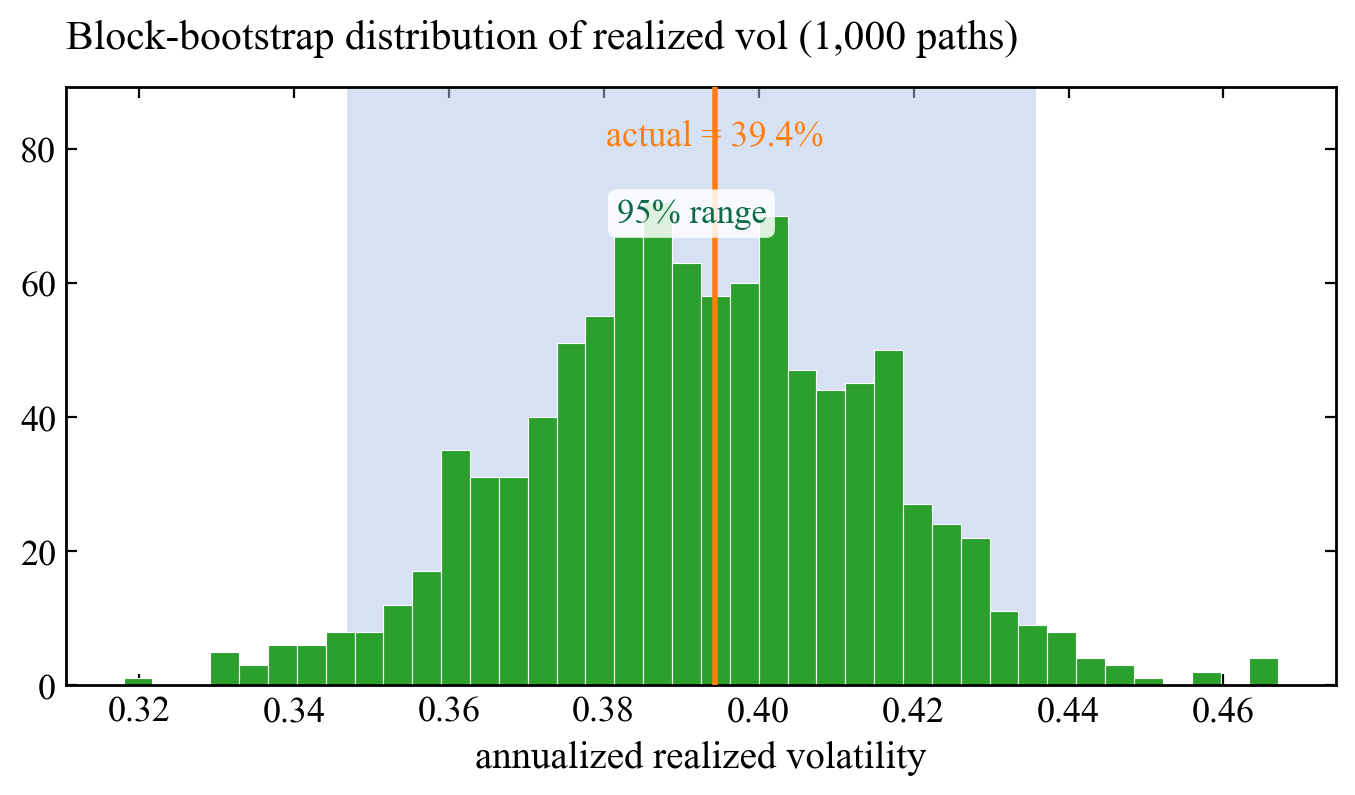

In [8]:
rng = np.random.default_rng(7)
N_PATHS = 1000
realized_vol = np.empty(N_PATHS)
for b in range(N_PATHS):
    r_star = log_ret[stationary_bootstrap_indices(n_ret, MEAN_BLOCK_LEN, rng)]
    realized_vol[b] = r_star.std(ddof=1) * np.sqrt(252)

real_vol = log_ret.std(ddof=1) * np.sqrt(252)
lo, hi = np.percentile(realized_vol, [2.5, 97.5])

fig, ax = plt.subplots(figsize=(7.0, 4.2), dpi=200)
ax.axvspan(lo, hi, color=BLUE_FILL, alpha=0.5, zorder=1, linewidth=0)
ax.hist(realized_vol, bins=40, color=AQUA, edgecolor="white", linewidth=0.4, zorder=2)
ax.axvline(real_vol, color=ORANGE, linewidth=2, zorder=3)

style_axes(ax)
ax.set_xlabel("annualized realized volatility")
ax.set_title(
    f"Block-bootstrap distribution of realized vol ({N_PATHS:,} paths)",
    fontsize=15,
    color=INK,
    loc="left",
    pad=14,
)

ymax = ax.get_ylim()[1]
ax.set_ylim(0, ymax * 1.18)
ax.text(
    real_vol,
    ymax * 1.05,
    f"actual = {real_vol:.1%}",
    ha="center",
    va="bottom",
    color=ORANGE,
    fontsize=13,
)
ax.text(
    (lo + hi) / 2,
    ymax * 0.93,
    "95% range",
    ha="center",
    va="center",
    color="#0d6b4a",
    fontsize=12.5,
    zorder=4,
    bbox={
        "facecolor": "white",
        "edgecolor": "none",
        "alpha": 0.85,
        "boxstyle": "round,pad=0.25",
    },
)

fig.tight_layout()
fig.savefig(f"{FIGDIR}/btc_bootstrap_vol_distribution.pdf")

print(f"actual realized vol = {real_vol:.4f}")
print(f"bootstrap 95% range = ({lo:.4f}, {hi:.4f})")

## Why resample log-returns, not raw prices (`Why do we need a Block Bootstrap?` slide)

Volatile period: BTCUSDT daily, 2022 (LUNA collapse in May, 3AC, FTX collapse in November --- \$47{,}723 $\to$ \$16{,}542, a genuinely rough year). Two "bootstraps" of this series:

- **naive**: resample the raw price _levels_ with replacement, and treat that sequence as a price path.
- **correct**: resample the daily log-returns with replacement, cumulate from $P_0$.

Volatility clustering is deliberately _not_ addressed here (that's the block-bootstrap payoff, next section) --- this cell only makes the case for _log-returns over raw prices_ as the resampling unit.


real 2022: 47723 -> 16542  (-65.3%)
worst real single-day move  = 15.38%
naive price-bootstrap: 69.0% of steps exceed that


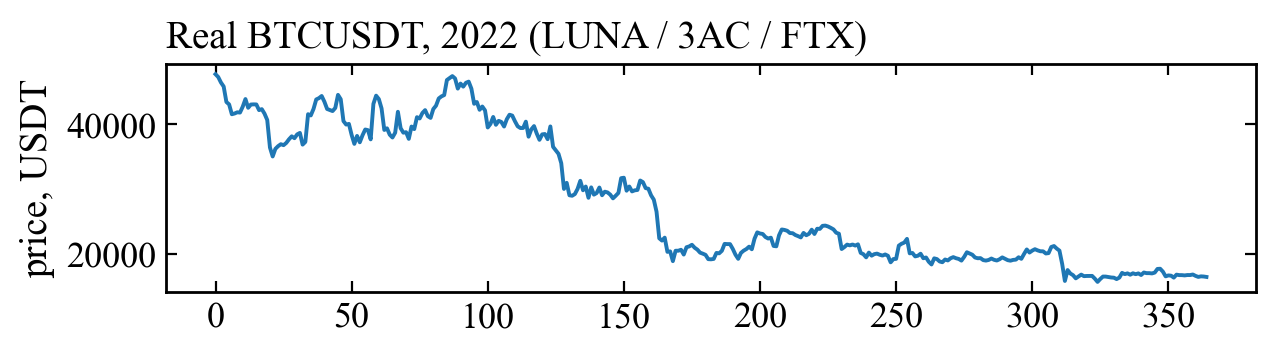

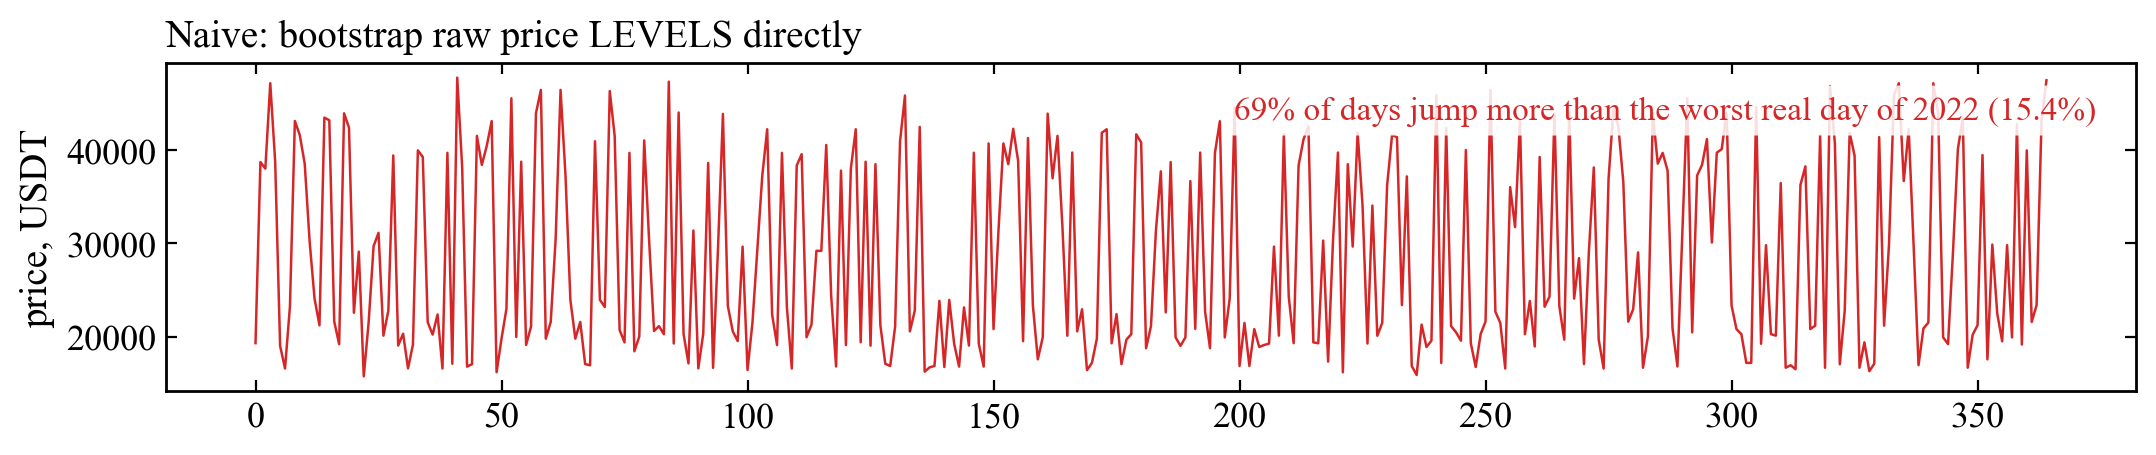

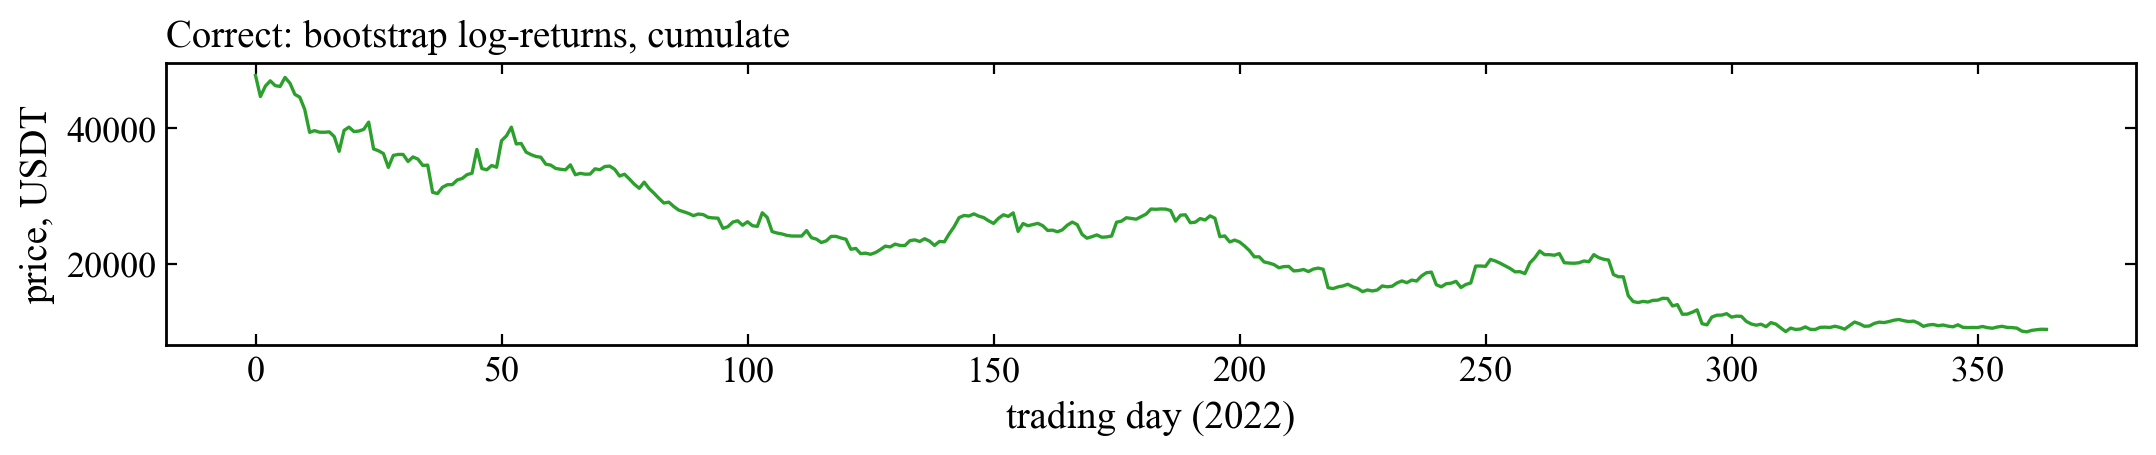

In [9]:
RED = "#d62728"

btc22 = pd.read_csv(f"{DATADIR}/btcusdt_daily_2022.csv", parse_dates=["date"])
close22 = btc22["close"].to_numpy()
n22 = len(close22)
log_ret22 = np.diff(np.log(close22))
P0_22 = close22[0]

rng = np.random.default_rng(3)

# naive: bootstrap the raw price LEVELS directly, treat the resample as if it were a path
naive_prices = rng.choice(close22, size=n22, replace=True)

# correct: bootstrap log-returns, cumulate into a price path
boot_ret22 = rng.choice(log_ret22, size=n22 - 1, replace=True)
ret_boot_path = np.concatenate([[P0_22], P0_22 * np.exp(np.cumsum(boot_ret22))])

# quantify the absurdity: day-to-day % moves
real_daily_pct = np.abs(np.diff(close22) / close22[:-1])
naive_daily_pct = np.abs(np.diff(naive_prices) / naive_prices[:-1])
real_max_move = real_daily_pct.max()
frac_exceeding = (naive_daily_pct > real_max_move).mean()

t22 = np.arange(n22)

# Three SEPARATE single-panel figures (not one combined/cropped image) --
# each placed into its own cell on the "Offtop" slide, so nothing gets clipped.
# Kept short (small figsize height) since three of them have to stack on one slide.

fig, ax = plt.subplots(figsize=(6.6, 2), dpi=200)
ax.plot(t22, close22, color=BLUE, linewidth=1.4)
style_axes(ax)
ax.set_title("Real BTCUSDT, 2022 (LUNA / 3AC / FTX)", fontsize=14, loc="left")
ax.set_ylabel("price, USDT")
fig.tight_layout()
fig.savefig(f"{FIGDIR}/btc_2022_real.pdf")

fig, ax = plt.subplots(figsize=(11.0, 2.5), dpi=200)
ax.plot(t22, naive_prices, color=RED, linewidth=0.9)
style_axes(ax)
ax.set_title("Naive: bootstrap raw price LEVELS directly", fontsize=14, loc="left")
ax.set_ylabel("price, USDT")
ax.text(
    0.98,
    0.90,
    f"{frac_exceeding:.0%} of days jump more than the worst real day of 2022 ({real_max_move:.1%})",
    transform=ax.transAxes,
    ha="right",
    va="top",
    color=RED,
    fontsize=12,
    zorder=5,
    bbox={
        "facecolor": "white",
        "edgecolor": "none",
        "alpha": 0.85,
        "boxstyle": "round,pad=0.3",
    },
)
fig.tight_layout()
fig.savefig(f"{FIGDIR}/btc_2022_naive.pdf")

fig, ax = plt.subplots(figsize=(11.0, 2.5), dpi=200)
ax.plot(t22, ret_boot_path, color=AQUA, linewidth=1.2)
style_axes(ax)
ax.set_title("Correct: bootstrap log-returns, cumulate", fontsize=14, loc="left")
ax.set_ylabel("price, USDT")
ax.set_xlabel("trading day (2022)")
fig.tight_layout()
fig.savefig(f"{FIGDIR}/btc_2022_logreturn.pdf")

print(f"real 2022: {P0_22:.0f} -> {close22[-1]:.0f}  ({(close22[-1] / P0_22 - 1):.1%})")
print(f"worst real single-day move  = {real_max_move:.2%}")
print(f"naive price-bootstrap: {frac_exceeding:.1%} of steps exceed that")